<a href="https://colab.research.google.com/github/PrasadJagdale1939/Google_Colab_Practice/blob/main/House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from sklearn.model_selection import GridSearchCV


In [ ]:
df = pd.read_csv("train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.shape

(1460, 81)

In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
df.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

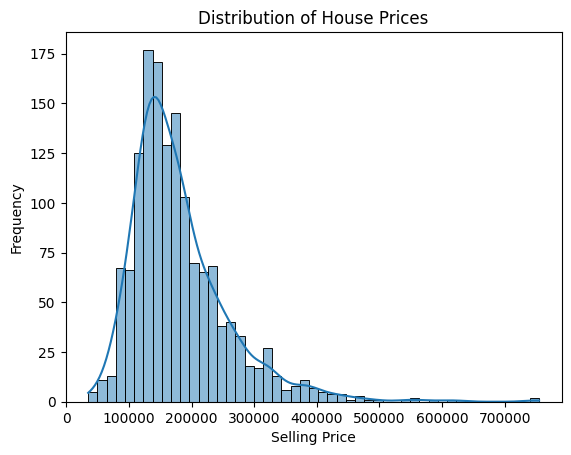

In [ ]:
sns.histplot(df["SalePrice"],kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.show()

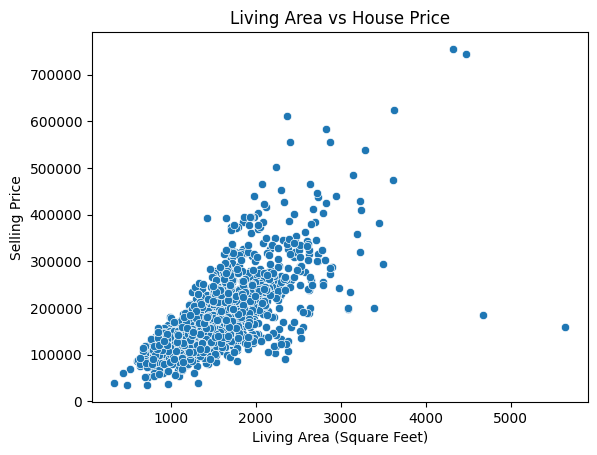

In [ ]:
sns.scatterplot(data=df,x="GrLivArea",y="SalePrice")
plt.title("Living Area vs House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Selling Price")

plt.show()

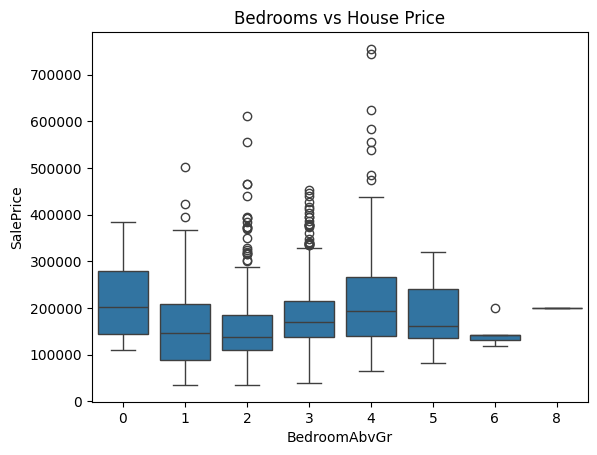

In [ ]:
sns.boxplot(data=df,x="BedroomAbvGr",y="SalePrice")
plt.title("Bedrooms vs House Price")
plt.show()

Text(0.5, 1.0, 'Overall Quality vs House Price')

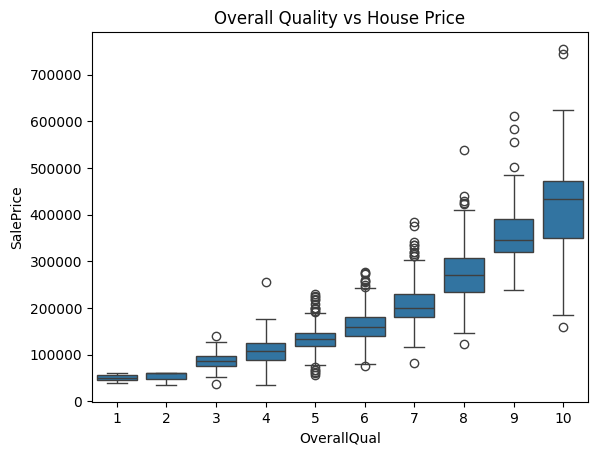

In [ ]:
sns.boxplot(data=df,x="OverallQual",y="SalePrice")
plt.title("Overall Quality vs House Price")

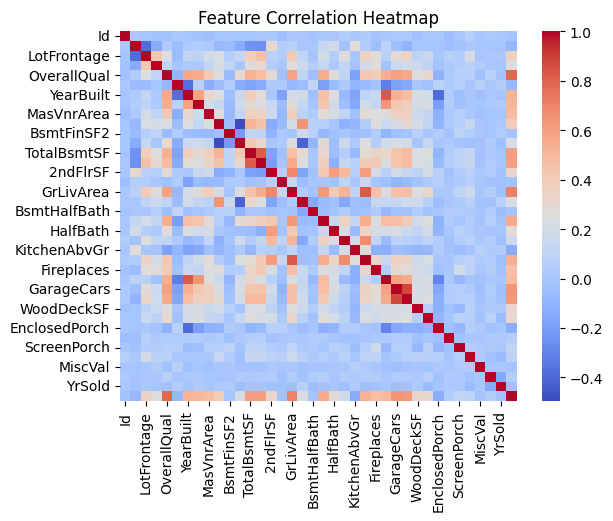

In [ ]:
correlation = df.select_dtypes(include=["number"]).corr()

sns.heatmap(correlation,cmap="coolwarm",annot=False )
plt.title("Feature Correlation Heatmap")

plt.show()

In [ ]:
price_correlation = correlation["SalePrice"].sort_values(ascending=False)
print(price_correlation.head(15))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


In [ ]:
missing_values= df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print(missing_values)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


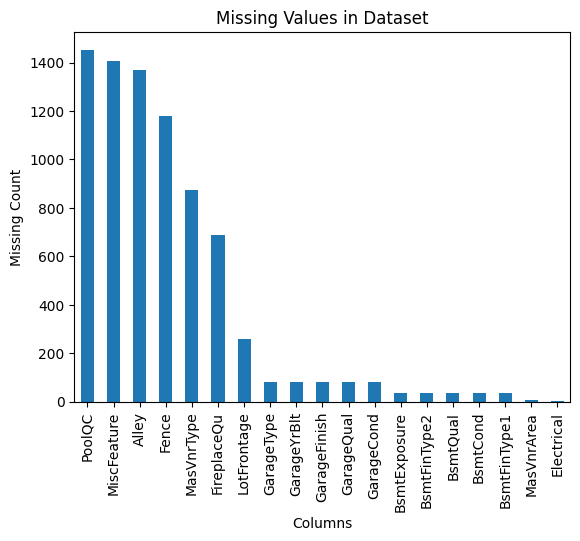

In [ ]:
missing_values.plot(kind="bar")

plt.title("Missing Values in Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Count")

plt.show()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop_duplicates()

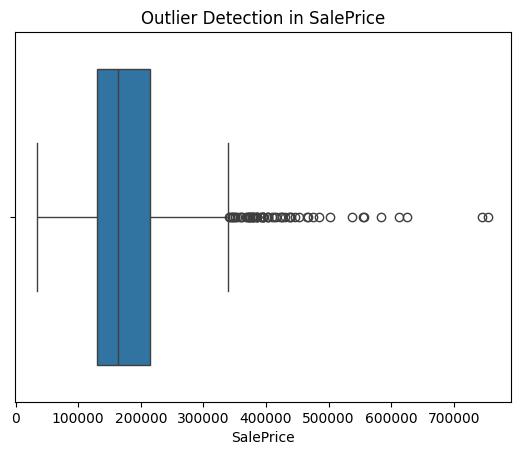

In [ ]:
sns.boxplot(x=df["SalePrice"])

plt.title("Outlier Detection in SalePrice")

plt.show()

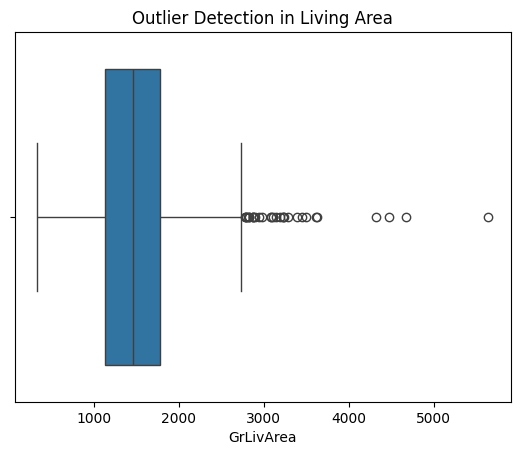

In [ ]:
sns.boxplot(x=df["GrLivArea"])

plt.title("Outlier Detection in Living Area")

plt.show()

In [ ]:
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

df["TotalBathrooms"] = ( df["FullBath"]+ 0.5 * df["HalfBath"]+ df["BsmtFullBath"]+ 0.5 * df["BsmtHalfBath"])

df["TotalArea"] = (df["TotalBsmtSF"]+ df["1stFlrSF"]+ df["2ndFlrSF"])

print(df[["HouseAge", "TotalBathrooms", "TotalArea"]].head())

   HouseAge  TotalBathrooms  TotalArea
0         5             3.5       2566
1        31             2.5       2524
2         7             3.5       2706
3        91             2.0       2473
4         8             3.5       3343


In [ ]:
df =df.drop("Id", axis=1)
X =df.drop("SalePrice", axis=1)
y =df["SalePrice"]

In [ ]:
X.shape, y.shape

((1460, 82), (1460,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)


In [ ]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((1168, 82), (292, 82), (1168,), (292,))

In [ ]:
numeric_features =X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features =X_train.select_dtypes(include=["object"]).columns

In [ ]:
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))]
)

preprocessor = ColumnTransformer(
    transformers=[("num", numeric_transformer, numeric_features),("cat", categorical_transformer, categorical_features)]
)

**Model training**

In [ ]:
baseline_model = Pipeline(steps=[("preprocessor", preprocessor),("model", DummyRegressor(strategy="mean"))])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'L...
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object'))])),
                ('model', DummyRegressor())])

In [ ]:
linear_model = Pipeline(steps=[("preprocessor", preprocessor),("model", LinearRegression())])
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'L...
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object'))])),
                ('model', LinearRegression())])

In [ ]:
random_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=15,
        random_state=42,
        n_jobs=1
    ))
])

In [ ]:
gradient_model = Pipeline([("preprocessor", preprocessor),("model", GradientBoostingRegressor(n_estimators=100,random_state=42))])

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
gradient_model = Pipeline(steps=[("preprocessor", preprocessor),("model", GradientBoostingRegressor(n_estimators=100,random_state=42))])
models = {
    "Baseline": baseline_model,
    "Linear Regression": linear_model,
    "Random Forest": random_model,
    "Gradient Boosting": gradient_model
}

In [ ]:
results = []

for name, model in models.items():

    print("Training:", name)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=3,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    rmse = -scores.mean()

    results.append({
        "Model": name,
        "Cross Validation RMSE": rmse
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by="Cross Validation RMSE"
))

Training: Baseline
Training: Linear Regression
Training: Random Forest
Training: Gradient Boosting
               Model  Cross Validation RMSE
3  Gradient Boosting           26328.273362
2      Random Forest           28791.699534
1  Linear Regression           38363.794451
0           Baseline           77198.855281


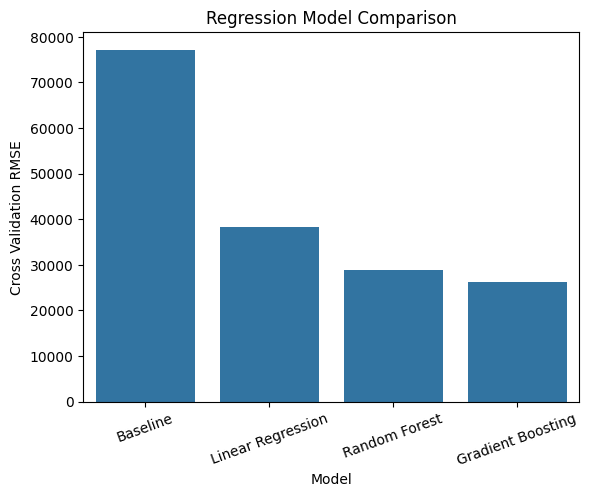

In [ ]:
sns.barplot(data=results_df,x="Model",y="ross Validation RMSE")
plt.title("Regression Model Comparison")
plt.xticks(rotation=20)

plt.show()

In [ ]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

In [ ]:
grid_search = GridSearchCV(estimator=random_model, param_grid=param_grid ,cv=5 ,scoring="neg_root_mean_squared_error" ,n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmt...
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object'))])),
                                       ('model',
                                        RandomForestRegressor(max_depth=15,
                                                              n_estimators=50,
                                                              n_jobs=1,
                                                              random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 10, 20],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='neg_root_mean_squared_error', verbose=1)

In [ ]:
print(grid_search.best_params_)
print(-grid_search.best_score_)

{'model__max_depth': 20, 'model__min_samples_split': 2, 'model__n_estimators': 100}
29049.869190216756


In [ ]:
best_model = grid_search.best_estimator_

In [ ]:
y_pred =best_model.predict(X_test)

print("Actual Prices:")
print(y_test.head())

print("\nPredicted Prices:")
print(y_pred[:5])

Actual Prices:
892     154500
1105    325000
413     115000
522     159000
1036    315500
Name: SalePrice, dtype: int64

Predicted Prices:
[139519.50714286 352002.41       112741.66666667 160955.
 323621.79      ]


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Final Model Performance")
print(f"MAE:{mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2 Score: {r2}")

Final Model Performance
MAE: 18049.05891850403
MSE: 906380426.2469568
RMSE: 30106.152631097797
R2 Score: 0.8818328710195305


In [ ]:
comparison = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": y_pred})
print(comparison.head(10))

   Actual Price  Predicted Price
0        154500    139519.507143
1        325000    352002.410000
2        115000    112741.666667
3        159000    160955.000000
4        315500    323621.790000
5         75500     88197.000000
6        311500    203784.130000
7        146000    151746.500000
8         84500     87477.000000
9        135500    130266.107143


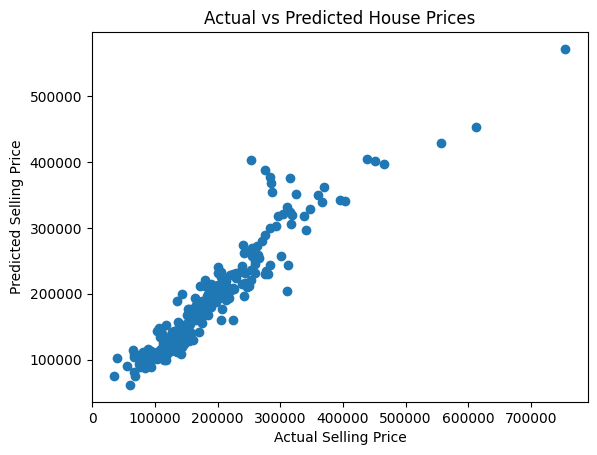

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

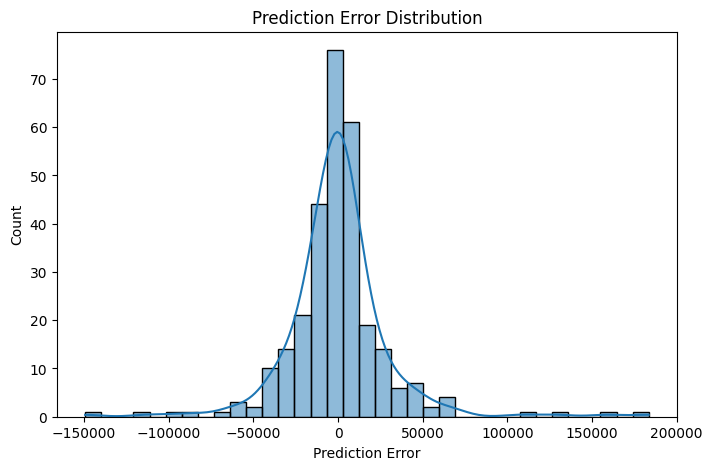

In [ ]:
errors =y_test - y_pred
sns.histplot(errors, kde=True)
plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.show()

In [ ]:
print(f"Average Absolute Error: {np.abs(errors).mean()}")

Average Absolute Error: 18049.05891850403


In [ ]:
print("Dataset Size:", df.shape)
print("Best Model: Random Forest Regressor ")
print(f"MAE:{round(mae, 2)}")
print(f"MSE: {round(mse, 2)}")
print(f"RMSE: {round(rmse, 2)}")
print(f"R2 Score: {round(r2, 4)}")

Dataset Size: (1460, 83)
Best Model: Random Forest Regressor
MAE: 18049.06
MSE: 906380426.25
RMSE: 30106.15
R2 Score: 0.8818


In [ ]:
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

importance = best_model.named_steps['model'].feature_importances_
importance_df =pd.DataFrame({'Feature': feature_names,'Importance': importance})
importance_df =importance_df.sort_values(by="Importance",ascending=False).head(15)

print(importance_df)

                 Feature  Importance
3       num__OverallQual    0.386056
38        num__TotalArea    0.364147
13         num__2ndFlrSF    0.027757
5         num__YearBuilt    0.013985
2           num__LotArea    0.011760
37   num__TotalBathrooms    0.011443
8        num__BsmtFinSF1    0.011078
36         num__HouseAge    0.010463
1       num__LotFrontage    0.010413
6      num__YearRemodAdd    0.010224
15        num__GrLivArea    0.009846
25       num__GarageCars    0.009826
26       num__GarageArea    0.008500
183     cat__BsmtQual_Ex    0.006963
10        num__BsmtUnfSF    0.006787


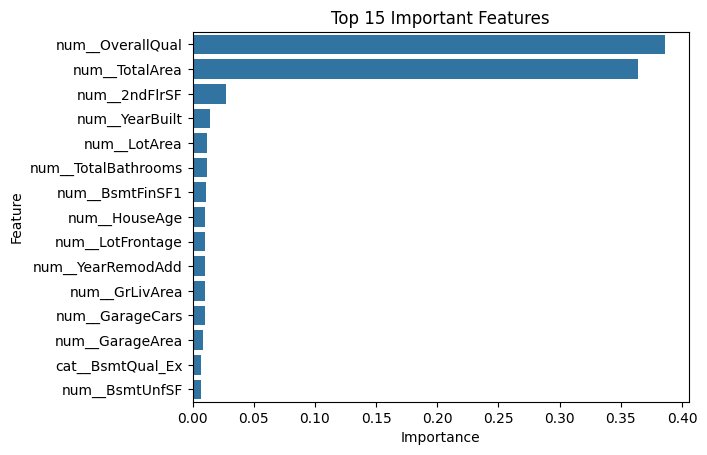

In [ ]:
sns.barplot(data=importance_df,x="Importance",y="Feature")
plt.title("Top 15 Important Features")

plt.show()

## 14. Project Outcome and Conclusion

### Project Outcome :

The House Price Prediction project was successfully developed using Machine Learning regression algorithms.

The Ames Housing dataset was used to train and evaluate the models. The following tasks were performed:

1. Collected and loaded the housing dataset.
2. Performed Exploratory Data Analysis (EDA) to understand housing price distributions and relationships between property features.
3. Cleaned the dataset by handling missing values and duplicate records.
4. Performed feature engineering by creating new features such as House Age, Total Bathrooms, and Total Area.
5. Applied data preprocessing techniques, including missing-value imputation, One-Hot Encoding, and feature scaling.
6. Divided the dataset into 80% training data and 20% testing data.
7. Implemented four models: Dummy Regressor (Baseline), Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor.
8. Compared model performance using cross-validation and RMSE.
9. Applied hyperparameter tuning to improve the Random Forest model.
10. Evaluated the final model using MAE, MSE, RMSE, and R² score.

### Conclusion :

This project demonstrates how Machine Learning regression techniques can be used to predict residential property prices based on various housing characteristics.

The analysis helps understand the relationship between factors such as living area, overall quality, number of bedrooms, bathrooms, and property age with house selling prices.

Different regression algorithms were implemented and compared to identify a suitable predictive model. Data preprocessing, feature engineering, cross-validation, and hyperparameter tuning played important roles in developing the prediction system.

Overall, this project provided practical experience in the complete Machine Learning workflow, from data collection and analysis to model training, evaluation, and price prediction.
